### Project Title 
Employer Ratings Analysis of Indian Companies.
### Domain 
Human Resources Analytics

### Project Overview
Finding the right job in India’s bustling market—whether in a tech startup, a pharmaceutical plant, or a financial firm—is about much more than just a job title. Today, job seekers, HR professionals, and recruiters want the real story before making big career decisions. Instead of relying solely on glossy corporate brochures, they turn to review platforms like AmbitionBox and Glassdoor to get a genuine peek into company culture, fair pay, and what everyday work life actually looks like.
This project analyzes a dataset of 10,000 Indian company profiles. The dataset covers employee satisfaction ratings, industry classifications, headquarters locations, and activity metrics including total review volume, salary submissions, interview reports, active job postings, benefit listings, and uploaded photos.

### Business Problem
Star ratings don't always tell the whole truth. A high rating backed by just a handful of reviews means very little compared to a slightly lower rating built on thousands of honest employee experiences.   Beyond ratings, hiring activity and pay disclosures vary wildly from one industry or city to another. This leaves two big gaps: HR leaders lack realistic benchmarks to compare their company's reputation against direct competitors, and candidates find it tough to separate genuinely great employers from small firms with inflated scores.

### Project Objectives

**Industry Benchmark Analysis:** Identify the top 10 company types by company count and compare their average ratings to highlight the highest- and lowest-rated sectors.

**Rating Reliability & Evidence Volume:** Measure the proportion of company profiles that meet a reliability threshold of $\ge 100$ employee reviews and evaluate how this share differs across sectors.

**Geographic Distribution & Hiring Activity:** Identify the top 10 headquarters cities by company volume and evaluate regional differences in average employee ratings and active job postings.

**Activity Correlation:** Quantify the linear relationships (Pearson correlation coefficients) between average employee ratings and review volume, salary reports, interview reports and job openings.

**Data Quality & Missingness Management:** Quantify missing values in secondary metrics (such as active job openings) and establish deterministic data-cleaning protocols.

### Business Value & Use Case

Job Seekers: Gain a data-backed method to evaluate job prospects by balancing overall star ratings with sample size (review count) and hiring volume.   
HR & Employer Branding Teams: Compare internal ratings, interview experiences, and benefit counts against direct industry competitors and city-level peers to refine talent acquisition strategies.   
Recruiters & Analysts: Track hiring density and salary submission activity across industries and metropolitan hubs to identify competitive talent markets.


### Dataset Information

Source URL: https://www.kaggle.com/datasets/dhruvnegi2006/companies-in-india   
File Format: CSV file   
Dataset Size: 10,000 rows $\times$ 11 columns (1 index column + 10 analytical attributes)  
Record Representation: Each row represents one company profile listing.

### Key Fields
name - Official company name

rating - Average employee satisfaction rating ($1.0 - 5.0$)

company_type - Industry or company category classification

hq - Headquarters city and location footprint (often including counts of other locations)

number_of_reviews - Total count of employee reviews stored as text (e.g., 54k, 1.2L)

salaries - Total count of submitted salary reports

interviews - Total count of interview experience reports 

jobs - Total count of active job postings

benefits - Total count of employee benefit mentions


### Planned Analysis
In this project, I want to explore and analyze public employer profile data for 10,000 Indian companies. I will use Python to clean the dataset and examine how company sector, location, and employee engagement metrics relate to overall ratings.

I plan to focus on the following areas:

**1.Cleaning and preprocessing company data:** I will remove redundant index columns, convert shorthand text counts (such as 54k or 1.2L) into numerical values, and extract clean headquarters city names from location strings.

**2.Benchmarking company sectors:** I will identify the top 10 company types by company volume and compare their average employee ratings to see which industries score highest and lowest.

**3.Evaluating rating reliability:** I will calculate the proportion of companies meeting a threshold of 100 or more employee reviews to understand how statistically reliable the ratings are across different sectors.

**4.Analyzing geographical patterns:** I will group companies by their primary headquarters cities to evaluate regional variations in average ratings and active job postings.

**5.Testing activity correlations:** I will compute linear correlation coefficients (Pearson $r$) between average employee ratings and engagement metrics like review volume, salary submissions, interview reports and active job openings.

**6.Managing missing data and summarizing findings:** I will quantify missing values in secondary metrics (such as active job openings), establish clear data-cleaning protocols, and use charts and summary tables to make the results clear and actionable.   Through this analysis, I hope to provide job seekers, HR teams, and recruiters with data-backed benchmarks for evaluating company reputations across India

### Scope & Limitations
**In-Scope:** 
* Analysis of 10,000 public company profiles in India across major industries and metropolitan hubs.  
* Preprocessing and standardization of company attributes: star ratings, sector types, primary headquarters cities, review counts, salary reports, interview reports, active job postings, and benefits.   
* Statistical benchmark analysis, rating reliability assessment ($\ge 100$ reviews), regional distribution mapping, and Pearson correlation testing across engagement metrics.

**Out-of-Scope:**

* Qualitative sentiment analysis or Natural Language Processing (NLP) of individual written employee reviews (as the dataset consists of aggregated numeric counts).
* Longitudinal or time-series analysis (the dataset represents a single static snapshot rather than historical trends over time).
* Global employer evaluation outside the Indian geographic market.

**Assumptions:**
* The dataset hosted on Kaggle provides a faithful aggregation of public employer profiles (sourced from portals like AmbitionBox).  
* String suffixes follow standard Indian numerical notation: k denotes thousands ($\times 1,000$) and L denotes lakhs ($\times 100,000$).

**Known Data Constraints:** 
* High proportion of missing values in secondary metrics, specifically active jobs (3,586 missing records) and photos (5,596 missing records).
* Presence of 598 duplicate profile records requiring systematic deduplication during preprocessing.
*  Sampling bias favoring companies with an online presence and active public employee feedback

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df = pd.read_csv(r"C:\Users\ajith\Desktop\Companies_in_India.csv\Companies_in_India.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
df.head()

Dataset loaded successfully!
Number of rows: 10000
Number of columns: 11


,Unnamed: 0,name,rating,company_type,hq,number_of_reviews,salaries,interviews,jobs,benefits,photos
0,0,TCS,3.3,IT Services & Consulting,Bengaluru +445 other locations,1.2L,10.2L,11.4k,4.5k,10.8k,93
1,1,Accenture,3.7,IT Services & Consulting,Bengaluru +260 other locations,74.3k,7.1L,9.4k,35.4k,6.8k,49
2,2,Wipro,3.6,IT Services & Consulting,Hyderabad +374 other locations,65.7k,4.9L,6.9k,310,4.8k,114
3,3,Cognizant,3.7,IT Services & Consulting,Hyderabad +233 other locations,62.1k,6.1L,6.5k,711,5.6k,102
4,4,Capgemini,3.6,IT Services & Consulting,Bengaluru +184 other locations,54k,4.9L,5.6k,2.2k,3.8k,42


In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         10000 non-null  int64  
 1   name               10000 non-null  str    
 2   rating             9991 non-null   float64
 3   company_type       10000 non-null  str    
 4   hq                 9726 non-null   str    
 5   number_of_reviews  10000 non-null  str    
 6   salaries           10000 non-null  str    
 7   interviews         10000 non-null  str    
 8   jobs               6414 non-null   str    
 9   benefits           10000 non-null  str    
 10  photos             4404 non-null   str    
dtypes: float64(1), int64(1), str(9)
memory usage: 1.5 MB


In [49]:
df.shape

(10000, 11)

In [50]:
df.dtypes

Unnamed: 0             int64
name                     str
rating               float64
company_type             str
hq                       str
number_of_reviews        str
salaries                 str
interviews               str
jobs                     str
benefits                 str
photos                   str
dtype: object

In [51]:
df.size

110000

In [52]:
df.nunique()

Unnamed: 0           10000
name                  9378
rating                  37
company_type           294
hq                    2743
number_of_reviews      939
salaries              1215
interviews             467
jobs                   315
benefits               465
photos                 129
dtype: int64

In [53]:
df.isnull().sum()

Unnamed: 0              0
name                    0
rating                  9
company_type            0
hq                    274
number_of_reviews       0
salaries                0
interviews              0
jobs                 3586
benefits                0
photos               5596
dtype: int64

**Initial Dataset Observations** 

Scale: 10,000 rows $\times$ 11 columns (10 analytical fields + index column Unnamed: 0).

Duplicates: 598 duplicate profile records identified for removal.

Formatting: Shorthand string counts (k for thousands, L for lakhs) in volume columns require numeric conversion.

Location Text: The hq column contains mixed strings requiring primary city extraction.

Data Gaps: Notable missing values in secondary metrics: jobs (3,586 missing) and photos (5,596 missing).  

In [54]:
df = df.drop(columns=['Unnamed: 0','photos'],errors='ignore')
df

,name,rating,company_type,hq,number_of_reviews,salaries,interviews,jobs,benefits
0,TCS,3.3,IT Services & Consulting,Bengaluru +445 other locations,1.2L,10.2L,11.4k,4.5k,10.8k
1,Accenture,3.7,IT Services & Consulting,Bengaluru +260 other locations,74.3k,7.1L,9.4k,35.4k,6.8k
2,Wipro,3.6,IT Services & Consulting,Hyderabad +374 other locations,65.7k,4.9L,6.9k,310,4.8k
3,Cognizant,3.7,IT Services & Consulting,Hyderabad +233 other locations,62.1k,6.1L,6.5k,711,5.6k
4,Capgemini,3.6,IT Services & Consulting,Bengaluru +184 other locations,54k,4.9L,5.6k,2.2k,3.8k
...,...,...,...,...,...,...,...,...,...
9995,Woodkraft (India) Private Limited,2.7,Real Estate,Bengaluru +9 other locations,111,496,5,5,7
9996,Mangalam Organics,3.7,Agro Chemicals,Mumbai +13 other locations,111,619,9,NaN,10
9997,Ecocat India,4.0,Auto Components,Faridabad +3 other locations,111,520,5,2,11
9998,infoAnalytica,3.2,Marketing & Advertising,Ahmedabad +3 other locations,111,428,9,6,14


####  Removed Unnecessary Columns – 'Unnamed:0' and 'photos' 

* This column may have been created when the dataset was previously saved as a CSV.
* It does not contain meaningful analytical information, so it is removed
* Dropped the photos column because it contained 5,596 missing values (56% of the total records).

In [55]:
df.duplicated().sum()

np.int64(598)

In [56]:
duplicates = df[df.duplicated()]
duplicates

,name,rating,company_type,hq,number_of_reviews,salaries,interviews,jobs,benefits
640,Marico,3.8,FMCG,Mumbai +187 other locations,1.6k,5.8k,107,34,165
800,Brillio,3.3,IT Services & Consulting,Bengaluru +14 other locations,1.3k,10.8k,141,78,78
881,Rupeek,4.1,FinTech,Bengaluru +56 other locations,1.2k,3.4k,133,32,58
1281,RR kabel,4.1,Electrical Equipment,Vadodara +118 other locations,841,3k,73,1,48
1361,Indo Autotech,3.9,Auto Components,Faridabad +34 other locations,798,2.8k,56,2,66
...,...,...,...,...,...,...,...,...,...
9973,The World Bank,3.8,Banking,Chennai +11 other locations,112,834,4,42,15
9977,Insphere Solutions,4.6,Emerging Technologies,New Delhi +6 other locations,112,179,43,6,1
9981,Druva,3.7,IT Services & Consulting,Pune +7 other locations,112,1k,25,13,17
9982,Finacus Solutions,2.7,IT Services & Consulting,Mumbai +5 other locations,112,706,14,2,7


In [57]:
initial_rows = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {initial_rows - len(df)} duplicates; {len(df)} rows remain")

Removed 598 duplicates; 9402 rows remain


#### Remove Duplicate Records

* Stored the initial number of rows in the dataset.
* Removed duplicate records using drop_duplicates().
* Reset the DataFrame index using reset_index(drop=True).
* Printed the number of removed duplicates and the remaining rows.

In [58]:
columns = ['number_of_reviews','salaries','interviews','jobs','benefits']
for col in columns:
    df[col] = df[col].astype(str).str.strip()
    df[col] = df[col].str.replace('K', 'e3', regex=False)
    df[col] = df[col].str.replace('k', 'e3', regex=False)
    df[col] = df[col].str.replace('L', 'e5', regex=False)
    df[col] = pd.to_numeric(df[col], errors='coerce')
df

,name,rating,company_type,hq,number_of_reviews,salaries,interviews,jobs,benefits
0,TCS,3.3,IT Services & Consulting,Bengaluru +445 other locations,120000.0,1020000.0,11400.0,4500.0,10800.0
1,Accenture,3.7,IT Services & Consulting,Bengaluru +260 other locations,74300.0,710000.0,9400.0,35400.0,6800.0
2,Wipro,3.6,IT Services & Consulting,Hyderabad +374 other locations,65700.0,490000.0,6900.0,310.0,4800.0
3,Cognizant,3.7,IT Services & Consulting,Hyderabad +233 other locations,62100.0,610000.0,6500.0,711.0,5600.0
4,Capgemini,3.6,IT Services & Consulting,Bengaluru +184 other locations,54000.0,490000.0,5600.0,2200.0,3800.0
...,...,...,...,...,...,...,...,...,...
9397,Woodkraft (India) Private Limited,2.7,Real Estate,Bengaluru +9 other locations,111.0,496.0,5.0,5.0,7.0
9398,Mangalam Organics,3.7,Agro Chemicals,Mumbai +13 other locations,111.0,619.0,9.0,NaN,10.0
9399,Ecocat India,4.0,Auto Components,Faridabad +3 other locations,111.0,520.0,5.0,2.0,11.0
9400,infoAnalytica,3.2,Marketing & Advertising,Ahmedabad +3 other locations,111.0,428.0,9.0,6.0,14.0


#### Convert Abbreviated Values into Numeric Format

- Selected five numerical columns for data cleaning.
- Removed unnecessary spaces from the values.
- Converted K and k into thousands (1,000).
- Converted L into lakhs (100,000).
- Converted the values into numeric format.
- Replaced invalid or missing values with NaN

In [59]:
df['hq_city'] = df['hq'].str.split('+').str[0].str.strip().fillna('Unknown')
df['other_locations'] = df['hq'].str.extract(r'\+(\d+)', expand=False).fillna(0).astype(int)
df

,name,rating,company_type,hq,number_of_reviews,salaries,interviews,jobs,benefits,hq_city,other_locations
0,TCS,3.3,IT Services & Consulting,Bengaluru +445 other locations,120000.0,1020000.0,11400.0,4500.0,10800.0,Bengaluru,445
1,Accenture,3.7,IT Services & Consulting,Bengaluru +260 other locations,74300.0,710000.0,9400.0,35400.0,6800.0,Bengaluru,260
2,Wipro,3.6,IT Services & Consulting,Hyderabad +374 other locations,65700.0,490000.0,6900.0,310.0,4800.0,Hyderabad,374
3,Cognizant,3.7,IT Services & Consulting,Hyderabad +233 other locations,62100.0,610000.0,6500.0,711.0,5600.0,Hyderabad,233
4,Capgemini,3.6,IT Services & Consulting,Bengaluru +184 other locations,54000.0,490000.0,5600.0,2200.0,3800.0,Bengaluru,184
...,...,...,...,...,...,...,...,...,...,...,...
9397,Woodkraft (India) Private Limited,2.7,Real Estate,Bengaluru +9 other locations,111.0,496.0,5.0,5.0,7.0,Bengaluru,9
9398,Mangalam Organics,3.7,Agro Chemicals,Mumbai +13 other locations,111.0,619.0,9.0,NaN,10.0,Mumbai,13
9399,Ecocat India,4.0,Auto Components,Faridabad +3 other locations,111.0,520.0,5.0,2.0,11.0,Faridabad,3
9400,infoAnalytica,3.2,Marketing & Advertising,Ahmedabad +3 other locations,111.0,428.0,9.0,6.0,14.0,Ahmedabad,3


#### Extract Headquarters City and Other Locations
- Separated the headquarters city and number of other locations from the hq column.
- Removed unnecessary spaces from the values.
- Replaced missing city names with Unknown and missing location counts with 0
- Converted the number of other locations into integer format.

In [60]:
df['name'] = df['name'].str.strip()
df['company_type'] = df['company_type'].str.strip()

#### Clean Text Columns
* Removed leading and trailing whitespace from the 'name' and 'company_type' columns using the str.strip() method to maintain text consistency and improve data quality.

In [61]:
df = df.dropna(subset=['rating','salaries']).reset_index(drop=True)

#### Remove Missing Values 
* Filtered out companies with unavailable ratings and salaries for accurate analysis.

In [62]:
cols = ['interviews','benefits']
df[cols] = df[cols].fillna(0).astype(int)

Handled missing values in the interviews and benefits columns by assigning zero, assuming that missing records indicate no reported activity.

In [63]:
df['jobs'] = df['jobs'].fillna(df.groupby('company_type')['jobs'].transform('median').round())                         
df['jobs'] = df['jobs'].fillna(df['jobs'].median()).round().astype(int)

Handled missing values in the jobs column using group-wise median imputation based on company type, followed by overall median imputation for remaining missing values. Rounded the values and converted them into integers

In [64]:
df = df.drop(columns=['hq'])

Drop the raw hq column (hq_city and other_locations replace it)

In [65]:
df.rename(columns={'salaries':'salary_records','interviews':'total_interviews','jobs':'job_postings','benefits':'benefits_count'},inplace=True)

In [66]:
df

,name,rating,company_type,number_of_reviews,salary_records,total_interviews,job_postings,benefits_count,hq_city,other_locations
0,TCS,3.3,IT Services & Consulting,120000.0,1020000.0,11400,4500,10800,Bengaluru,445
1,Accenture,3.7,IT Services & Consulting,74300.0,710000.0,9400,35400,6800,Bengaluru,260
2,Wipro,3.6,IT Services & Consulting,65700.0,490000.0,6900,310,4800,Hyderabad,374
3,Cognizant,3.7,IT Services & Consulting,62100.0,610000.0,6500,711,5600,Hyderabad,233
4,Capgemini,3.6,IT Services & Consulting,54000.0,490000.0,5600,2200,3800,Bengaluru,184
...,...,...,...,...,...,...,...,...,...,...
9385,Woodkraft (India) Private Limited,2.7,Real Estate,111.0,496.0,5,5,7,Bengaluru,9
9386,Mangalam Organics,3.7,Agro Chemicals,111.0,619.0,9,5,10,Mumbai,13
9387,Ecocat India,4.0,Auto Components,111.0,520.0,5,2,11,Faridabad,3
9388,infoAnalytica,3.2,Marketing & Advertising,111.0,428.0,9,6,14,Ahmedabad,3


In [67]:
columns = ['job_postings', 'salary_records', 'number_of_reviews']
df[columns] = df[columns].round().astype(int)

In [68]:
df['hq_city'] = df['hq_city'].astype('str')

In [69]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9390 entries, 0 to 9389
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               9390 non-null   str    
 1   rating             9390 non-null   float64
 2   company_type       9390 non-null   str    
 3   number_of_reviews  9390 non-null   int64  
 4   salary_records     9390 non-null   int64  
 5   total_interviews   9390 non-null   int64  
 6   job_postings       9390 non-null   int64  
 7   benefits_count     9390 non-null   int64  
 8   hq_city            9390 non-null   str    
 9   other_locations    9390 non-null   int64  
dtypes: float64(1), int64(6), str(3)
memory usage: 1.1 MB


In [70]:
df.isnull().sum()

name                 0
rating               0
company_type         0
number_of_reviews    0
salary_records       0
total_interviews     0
job_postings         0
benefits_count       0
hq_city              0
other_locations      0
dtype: int64

# Univariate Analysis 

In [71]:
df.describe()

,rating,number_of_reviews,salary_records,total_interviews,job_postings,benefits_count,other_locations
count,9390.000000,9390.000000,9.390000e+03,9390.000000,9390.000000,9390.000000,9390.000000
mean,3.726635,665.158466,2.966353e+03,57.513419,29.081896,53.511928,39.488818
std,0.425313,2648.979569,1.928820e+04,270.798666,386.759298,224.599101,80.603867
min,1.000000,111.000000,2.000000e+00,0.000000,1.000000,0.000000,0.000000
25%,3.500000,155.000000,5.840000e+02,10.000000,5.000000,9.000000,8.000000
50%,3.800000,235.000000,9.470000e+02,19.000000,8.000000,18.000000,18.000000
75%,4.000000,471.000000,1.900000e+03,41.000000,14.000000,39.000000,40.000000
max,4.900000,120000.000000,1.020000e+06,11400.000000,35400.000000,10800.000000,1962.000000


###  Exploratory Data Analysis (EDA)

####  1. Descriptive Statistical Analysis

This section provides a statistical summary of the numerical columns, including mean, median, standard deviation, minimum, maximum and quartile values.

#### Key Observations
- The average company rating is 3.73.
- Most numerical variables show considerable variation.
- Several variables have mean values higher than their median values, indicating potential right-skewed distributions.
- Further analysis is required to investigate extreme values.

In [72]:
print(f"Total Unique Company Types (Sectors): {df['company_type'].nunique()}")
print(f"Total Unique Headquarters Cities: {df['hq_city'].nunique()}")

Total Unique Company Types (Sectors): 293
Total Unique Headquarters Cities: 254


In [73]:
rating_analysis = df['rating'].describe()
print("Company Rating - Statistical Summary")
print(rating_analysis)
print("\nMode:", df['rating'].mode()[0])
print("Median:", df['rating'].median())
print("Skewness:", df['rating'].skew())

Company Rating - Statistical Summary
count    9390.000000
mean        3.726635
std         0.425313
min         1.000000
25%         3.500000
50%         3.800000
75%         4.000000
max         4.900000
Name: rating, dtype: float64

Mode: 3.9
Median: 3.8
Skewness: -0.5222157885310487


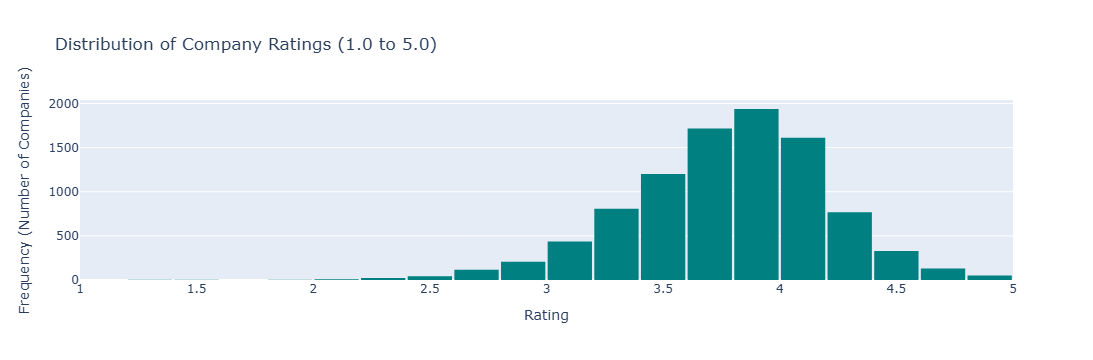

In [74]:
fig = px.histogram(df,x='rating',nbins=20,title='Distribution of Company Ratings (1.0 to 5.0)',color_discrete_sequence=['teal'],)
fig.update_layout(xaxis_title='Rating',yaxis_title='Frequency (Number of Companies)',bargap=0.05)
fig.show()

### Observation – Rating Distribution

The rating distribution is left-skewed (skewness about -0.52). About 74% of companies are rated between 3.0 and 4.0, and the median is 3.8, so most companies have moderate to good ratings.

In [75]:
top_10_types = (df['company_type'].value_counts().head(10))
top_10_types

company_type
IT Services & Consulting      1221
Engineering & Construction     456
Auto Components                403
Industrial Machinery           372
Pharma                         369
Software Product               316
Healthcare                     295
Education & Training           277
Financial Services             276
Internet                       253
Name: count, dtype: int64

Text(0, 0.5, 'Company Type')

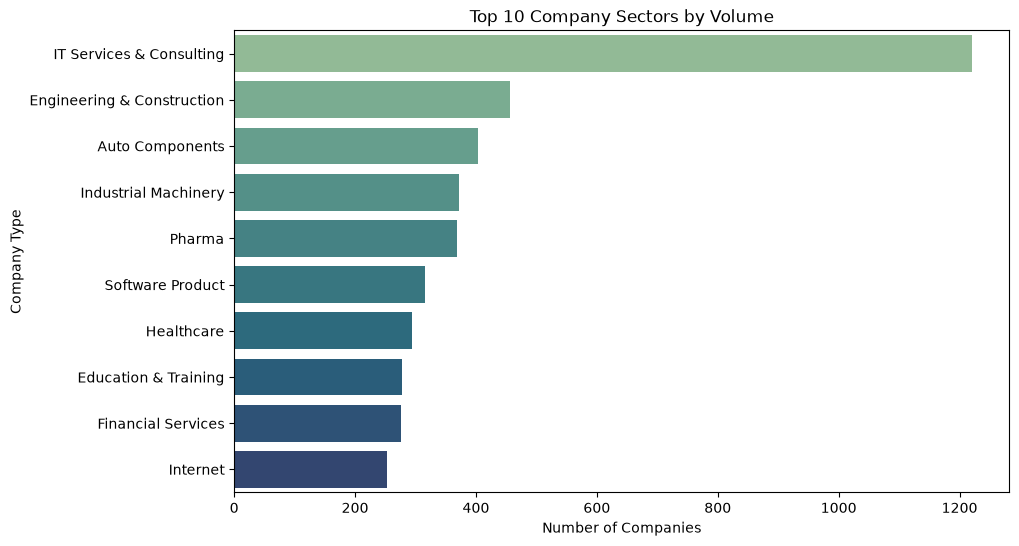

In [76]:
plt.figure(figsize=(10,6))
top_sectors = df['company_type'].value_counts().head(10)
sns.barplot(x=top_sectors.values,y=top_sectors.index,hue=top_sectors.index,palette='crest',legend=False)
plt.title('Top 10 Company Sectors by Volume')
plt.xlabel('Number of Companies')
plt.ylabel('Company Type')

#### Observation – Company Type Distribution

IT Services & Consulting has the highest number of companies (1,221) among the top 10 company types. Engineering & Construction ranks second with 456 companies. This indicates a strong representation of IT-related companies in the dataset.

In [77]:
top_cities = df[df['hq_city'] != 'Unknown']['hq_city'].value_counts().head(10)
print("\nTop 10 HQ Cities by Count (excluding Unknown):")
print(top_cities)


Top 10 HQ Cities by Count (excluding Unknown):
hq_city
Mumbai       1412
Bengaluru    1398
New Delhi     790
Chennai       740
Pune          730
Hyderabad     718
Gurugram      659
Noida         445
Kolkata       291
Ahmedabad     226
Name: count, dtype: int64


Text(0, 0.5, 'HQ City')

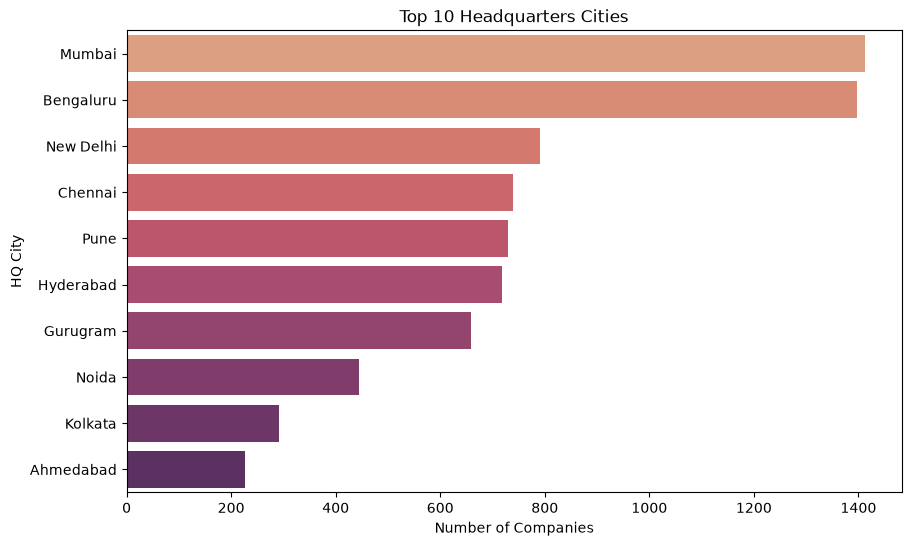

In [78]:
plt.figure(figsize=(10,6))
top_cities = df[df['hq_city'] != 'Unknown']['hq_city'].value_counts().head(10)
sns.barplot(x=top_cities.values,y=top_cities.index,hue=top_cities.index,palette='flare',legend=False)
plt.title('Top 10 Headquarters Cities')
plt.xlabel('Number of Companies')
plt.ylabel('HQ City')

#### Observation – Headquarters cities
Mumbai (1,412) and Bengaluru (1,398) lead by a wide margin, followed by New Delhi (790), Chennai (740) and Pune (730). Adding New Delhi, Gurugram and Noida together, the NCR region (about 1,900 companies) is larger than any single city. The 252 companies with an unknown headquarters are excluded from this ranking.

Min reviews: 111
>=100 reviews:100.0%
>=500 reviews:23.5%
>=1000 reviews:11.5%


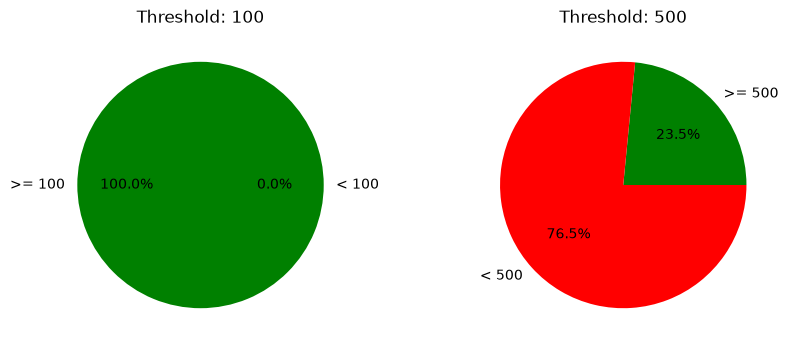

In [79]:
reviews = df['number_of_reviews']
print("Min reviews:", reviews.min())
for i in [100,500,1000]:
    print(f">={i} reviews:{(reviews >= i).mean():.1%}")
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax, i in zip(axes,[100,500]):
    proportions=[(reviews >= i).mean(),(reviews < i).mean()]
    ax.pie(proportions,labels=[f'>= {i}', f'< {i}'],autopct='%1.1f%%',colors=['green','red'])
    ax.set_title(f'Threshold: {i}')
plt.show()

#### Observation – Rating reliability
Every company in the cleaned data has at least 111 reviews, so 100% meet the ≥100 reviews threshold and this threshold cannot separate reliable from unreliable ratings. A stricter threshold of ≥500 reviews is therefore also reported: only about 23% of companies pass it. This should be stated clearly in the final report

# Bivariate Analysis

In [80]:
top_types = df['company_type'].value_counts().head(10).index
filtered_df = df[df['company_type'].isin(top_types)]
sector_avg = filtered_df.groupby('company_type')['rating'].mean().reset_index()
sector_avg = sector_avg.sort_values(by='rating', ascending=False)
sector_avg

,company_type,rating
2,Engineering & Construction,3.851096
4,Healthcare,3.828814
6,Industrial Machinery,3.800806
0,Auto Components,3.799256
1,Education & Training,3.742599
8,Pharma,3.732791
3,Financial Services,3.691667
7,Internet,3.613439
9,Software Product,3.567722
5,IT Services & Consulting,3.566339


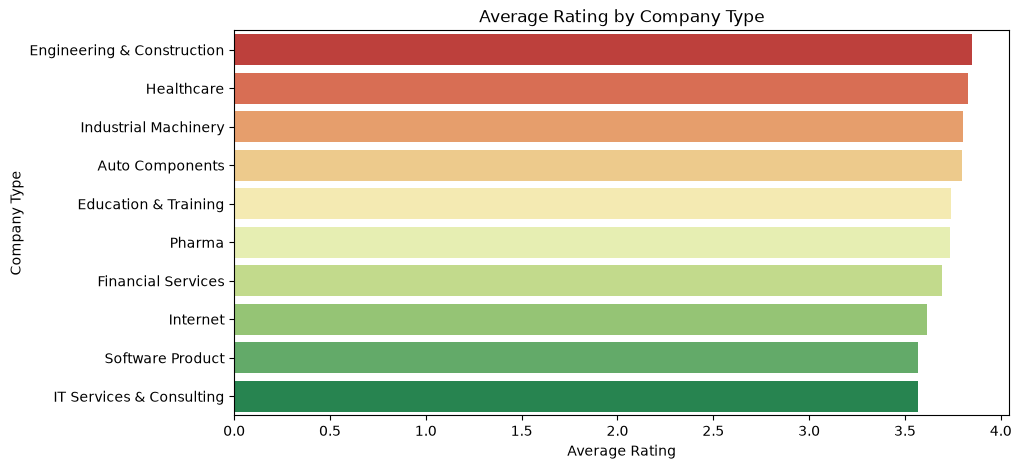

In [81]:
plt.figure(figsize=(10, 5))
sns.barplot(data=sector_avg,x='rating',y='company_type',hue='company_type',palette='RdYlGn',legend=False)
plt.title('Average Rating by Company Type')
plt.xlabel('Average Rating')
plt.ylabel('Company Type')
plt.show()

#### Observation – Company type vs rating
Among the top 10 types, Engineering & Construction (3.85) and Healthcare (3.83) have the highest average ratings, while IT Services & Consulting and Software Product (both 3.57) have the lowest. The gap is about 0.28 points. IT Services also has the highest median number of job postings (13).

In [82]:
top_city_list = df[df['hq_city'] != 'Unknown']['hq_city'].value_counts().head(10).index
city_stats = (df[df['hq_city'].isin(top_city_list)].groupby('hq_city').agg(companies=('name','count'),avg_rating=('rating','mean'),median_jobs=('job_postings','median')).round(2).sort_values('companies',ascending=False))
city_stats

,companies,avg_rating,median_jobs
hq_city,,,
Mumbai,1412,3.72,9.0
Bengaluru,1398,3.67,11.0
New Delhi,790,3.78,8.0
Chennai,740,3.74,8.0
Pune,730,3.70,9.0
Hyderabad,718,3.70,10.0
Gurugram,659,3.69,8.0
Noida,445,3.68,8.0
Kolkata,291,3.71,7.0


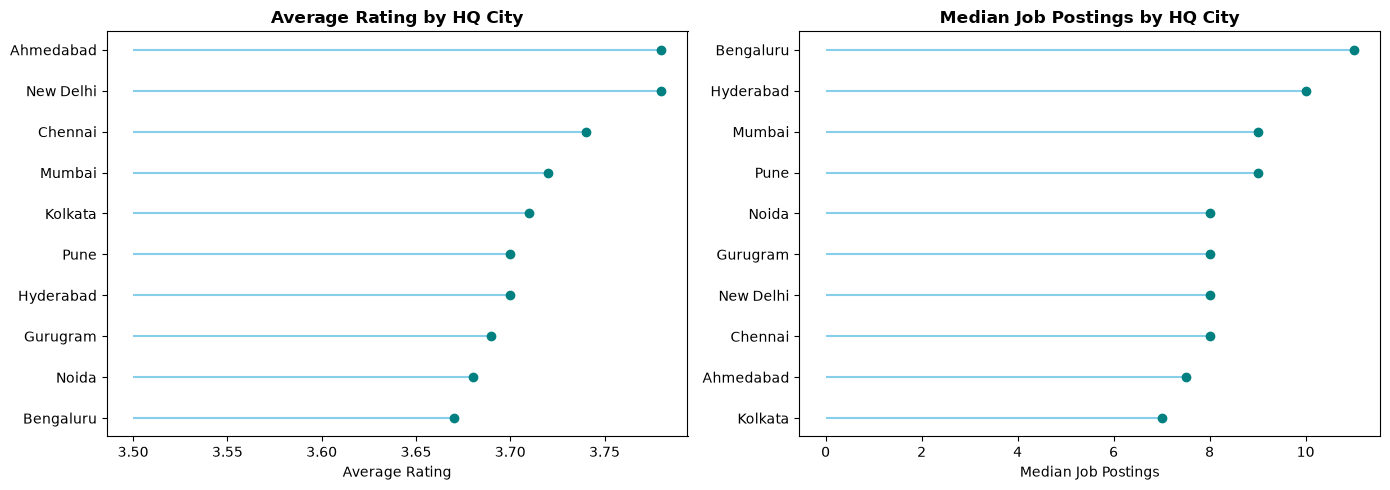

In [83]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cs = city_stats.sort_values('avg_rating')
axes[0].hlines(y=cs.index, xmin=3.5, xmax=cs['avg_rating'], color='skyblue')
axes[0].plot(cs['avg_rating'], cs.index, 'o', color='teal')
axes[0].set_title('Average Rating by HQ City', fontweight='bold')
axes[0].set_xlabel('Average Rating')
cs = city_stats.sort_values('median_jobs')
axes[1].hlines(y=cs.index, xmin=0, xmax=cs['median_jobs'], color='skyblue')
axes[1].plot(cs['median_jobs'], cs.index, 'o', color='teal')
axes[1].set_title('Median Job Postings by HQ City', fontweight='bold')
axes[1].set_xlabel('Median Job Postings')
plt.tight_layout()
plt.show()

#### Observation: Regional Rating and Job Postings
Among the top 10 headquarters cities, average ratings differ very little (3.67 to 3.78): New Delhi is highest and Bengaluru lowest. Median job postings are also close (7 to 11), with Bengaluru (11) and Hyderabad (10) highest. Bengaluru's average job postings (about 69) is far above its median, so a few very large employers pull the average up and the median is the fairer comparison.

Small cities were not used for this comparison: a city with only 1 or 2 companies (for example Hoshiarpur) gives an unreliable median.

In [84]:
df['review_band'] = pd.cut(df['number_of_reviews'], bins=[0, 150, 300, 1000, 5000, np.inf], labels=['<=150', '151-300', '301-1000', '1000-5000', '5000+'])
band_stats = df.groupby('review_band', observed=True)['rating'].agg(companies='size', mean='mean', std='std', min='min', max='max').round(2)
display(band_stats)

,companies,mean,std,min,max
review_band,,,,,
<=150,2171,3.71,0.47,1.5,4.9
151-300,3506,3.71,0.44,1.3,4.9
301-1000,2700,3.74,0.40,1.0,4.9
1000-5000,875,3.80,0.34,1.3,4.9
5000+,138,3.78,0.29,3.0,4.7


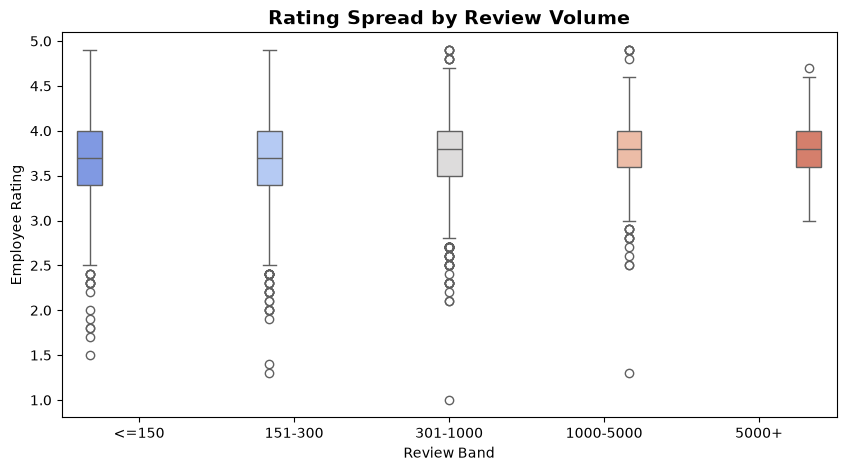

In [85]:
plt.figure(figsize=(10, 5))
sns.boxplot( data=df,x='review_band',y='rating',hue='review_band',palette='coolwarm',legend=False)
plt.title('Rating Spread by Review Volume', fontsize=14, fontweight='bold')
plt.xlabel('Review Band')
plt.ylabel('Employee Rating')
plt.show()

#### Observation – Review volume vs rating
Average rating rises slightly with review volume (3.71 for up to 150 reviews to 3.80 for 1,000-5,000), while the spread shrinks (standard deviation 0.47 to 0.29). Ratings built on more reviews are more consistent.

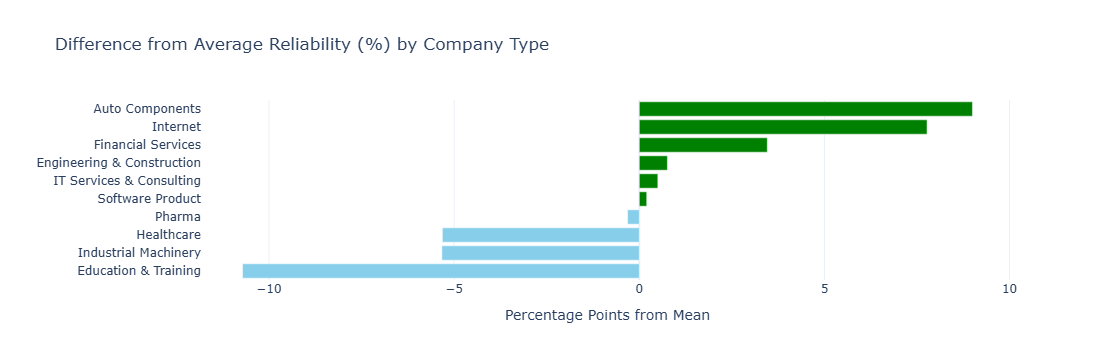

In [86]:
sub_df = df[df['company_type'].isin(top_types)].copy()
sub_df['reliable'] = sub_df['number_of_reviews'] >= 500

rel_pct = sub_df.groupby('company_type')['reliable'].mean() * 100
diff = (rel_pct - rel_pct.mean()).reset_index()
diff.columns = ['company_type', 'deviation']
diff = diff.sort_values('deviation', ascending=True)

diff['color'] = diff['deviation'].apply(lambda x: 'Above Average' if x >= 0 else 'Below Average')

fig = px.bar(diff,x='deviation',y='company_type',orientation='h',color='color',
    color_discrete_map={'Above Average': 'green', 'Below Average': 'skyblue'},
    title='Difference from Average Reliability (%) by Company Type',
    labels={'deviation': 'Percentage Points from Mean', 'company_type': ''})
fig.update_layout(xaxis_title='Percentage Points from Mean',yaxis_title='',template='plotly_white',showlegend=False)
fig.show()

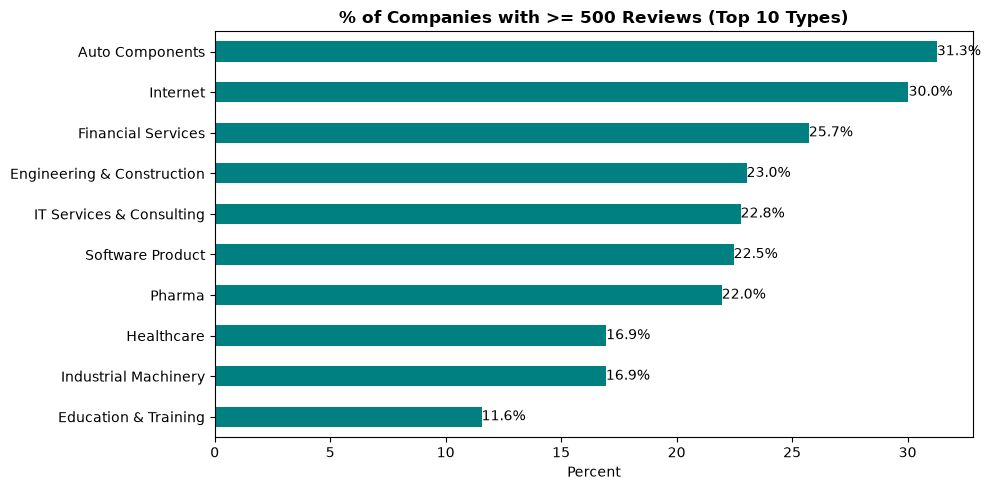

In [87]:
filtered_df = df[df['company_type'].isin(top_types)].copy()
filtered_df['reliable'] = filtered_df['number_of_reviews'] >= 500

rel = filtered_df.groupby('company_type')['reliable'].mean() * 100
rel = rel.sort_values()

plt.figure(figsize=(10, 5))
ax = rel.plot(kind='barh', color='teal')
ax.bar_label(ax.containers[0], fmt='%.1f%%')
plt.title('% of Companies with >= 500 Reviews (Top 10 Types)', fontsize=12, fontweight='bold')
plt.xlabel('Percent', fontsize=10)
plt.ylabel('')
plt.tight_layout()
plt.show()

#### Observation – Reliability by company type

Auto Components (31%) and Internet (30%) have the highest share of companies with at least 500 reviews. Education & Training has the lowest (12%), so ratings in that sector rest on thinner evidence than in other sectors.

# Multivariate Analysis

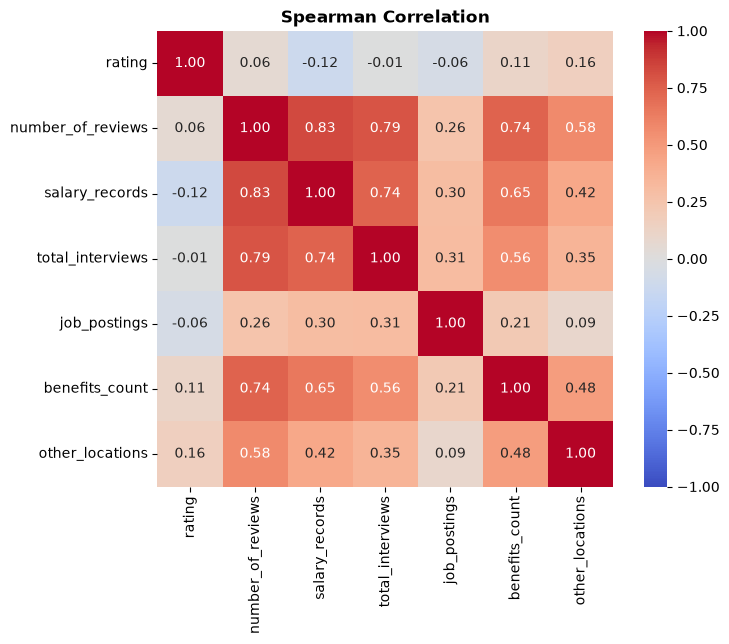

In [88]:
num_cols= ['rating','number_of_reviews','salary_records','total_interviews','job_postings','benefits_count','other_locations']
plt.figure(figsize=(8, 6.5))
sns.heatmap(df[num_cols].corr(method='spearman'),annot=True,fmt='.2f',cmap='coolwarm',center=0,vmin=-1,vmax=1,square=True,cbar=True)
plt.title('Spearman Correlation', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

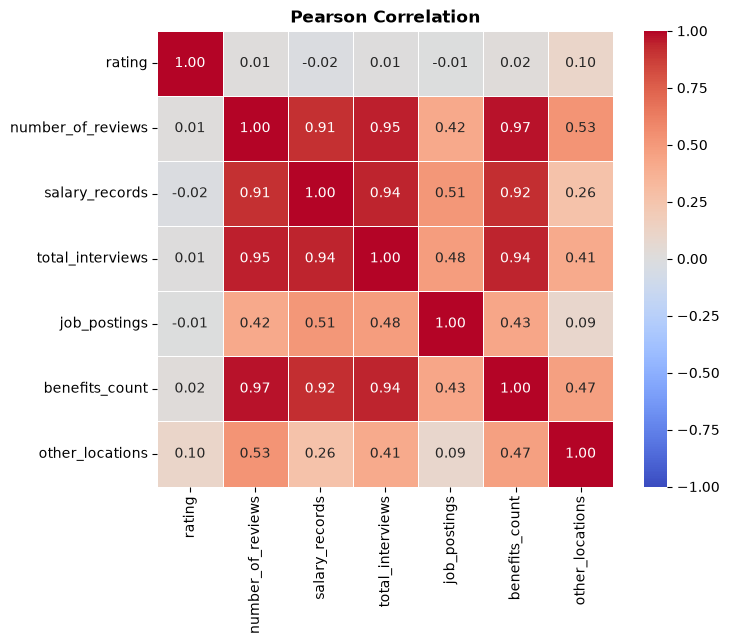

In [89]:
plt.figure(figsize=(8, 6.5))
sns.heatmap(df[num_cols].corr(method='pearson'),annot=True,fmt='.2f',cmap='coolwarm',center=0,vmin=-1,vmax=1,square=True,linewidths=.5,cbar=True)
plt.title('Pearson Correlation', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

#### Observation – Correlation heatmaps
Reviews, salary reports, interview reports and benefits form a block of very high correlations (0.91 to 0.97 in the Pearson map), which means they overlap and mostly describe company size (multicollinearity). job_postings is only moderately related to them (about 0.4 to 0.5). The rating row is close to zero in the Pearson map (between -0.02 and 0.10), so rating has no meaningful linear relationship with any activity metric. The Spearman map shows the same block, but with lower values (0.56 to 0.83), and a weak link between rating and number of other locations (0.16).

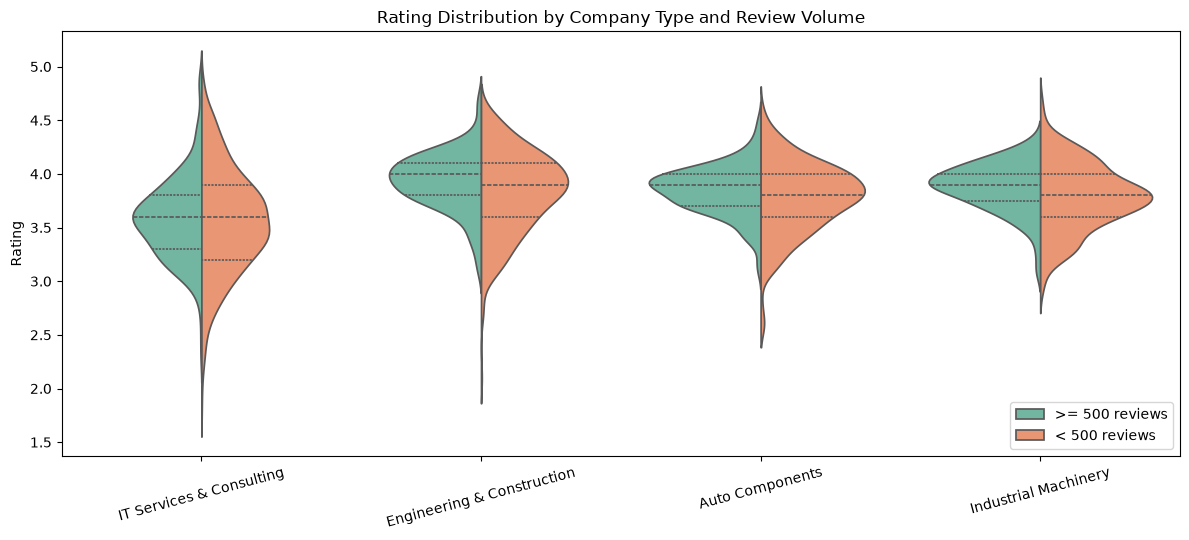

In [90]:
sub = df[df['company_type'].isin(top_types[:4])].copy()
sub['size_group'] = np.where(sub['number_of_reviews'] >= 500, '>= 500 reviews', '< 500 reviews')
plt.figure(figsize=(12, 5.5))
sns.violinplot(data=sub, x='company_type', y='rating', hue='size_group', split=True, inner='quart', palette='Set2')
plt.title('Rating Distribution by Company Type and Review Volume'); plt.xlabel(''); plt.ylabel('Rating')
plt.xticks(rotation=15); plt.legend(title='')
plt.tight_layout(); plt.show()

#### Observation – Type × review volume (violin)
In each of these four industries, companies with at least 500 reviews have a narrower rating distribution than those with fewer reviews (for example in IT Services the standard deviation is 0.38 against 0.49), again showing that ratings from more reviews are more consistent.

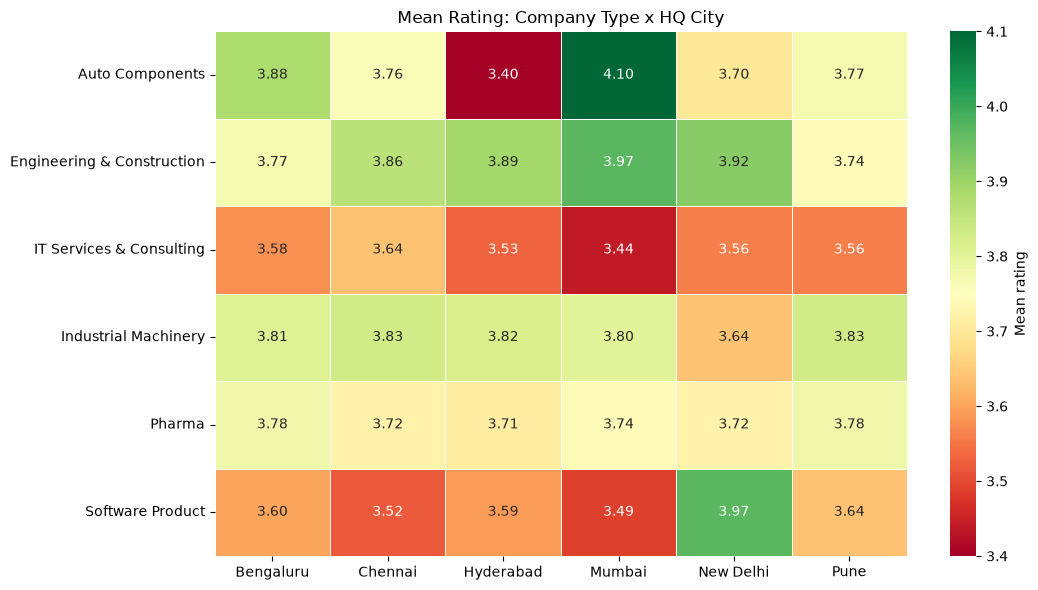

In [91]:
plt.figure(figsize=(11, 6))
sns.heatmap(pv, annot=True, fmt='.2f', cmap='RdYlGn', linewidths=.5, cbar_kws={'label': 'Mean rating'})
plt.title('Mean Rating: Company Type x HQ City'); plt.xlabel(''); plt.ylabel('')
plt.tight_layout(); plt.show()

#### Observation – Company type × city
Colour differences are stronger between rows (industries) than between columns (cities): IT Services stays at roughly 3.44 to 3.64 in every city, so the industry, not the city, drives the rating. Cells with very few companies (for example New Delhi and Software Product, only 3 companies with an average of 3.97) should not be trusted; always read the count table next to the average table.

# Final EDA Summary

**Data used:** 9,390 company profiles after removing 598 duplicates and 12 rows with missing rating or salary data. The `photos` column was dropped (56% missing). Missing `jobs` values (36% of rows) were filled with the sector median, and 253 missing headquarters were labelled Unknown.

**1. Ratings:** The average rating is 3.73 (median 3.8) and the distribution is left-skewed. About 74% of companies are rated between 3.0 and 4.0.

**2. Industry benchmark:** IT Services & Consulting is the largest sector (1,221 companies), followed by Engineering & Construction (456). Among the top 10 types, Engineering & Construction (3.85) and Healthcare (3.83) rate highest, and IT Services & Consulting and Software Product (both 3.57) rate lowest, a gap of about 0.28.

**3. Rating reliability:** Every company has at least 111 reviews, so all meet the 100-review threshold and it cannot separate reliable from unreliable ratings. With a stricter threshold of 500 reviews, 23% of companies qualify, ranging from 12% (Education & Training) to 31% (Auto Components) across the top 10 types. Ratings with more reviews are more consistent (standard deviation falls from 0.47 to 0.29 as review volume rises).

**4. Geography:** Mumbai (1,412) and Bengaluru (1,398) have the most companies, and the NCR (New Delhi, Gurugram, Noida) together has about 1,900. Average ratings across the top 10 cities are almost the same (3.67 to 3.78), and median job postings only range from 7 to 11. City matters little for rating.

**5. Correlation:** Rating is essentially uncorrelated with reviews, salary reports, interview reports, job postings and benefits (Pearson |r| of 0.02 or less, 0.10 for other locations). Those activity metrics are strongly correlated with each other (0.91 to 0.97) because they all reflect company size.

**6. Type and city together:** Industry explains rating differences more than city. Cells with very few companies are not reliable.

**Overall conclusion:** A high rating tells you nothing about how much evidence sits behind it. Readers should look at the number of reviews together with the rating, and compare a company with others in its own industry rather than across industries.

**Limitations:** Job postings are partly imputed (36%), the data is a single snapshot, and companies with an online presence are over-represented.